In [1]:

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import matplotlib.pyplot as plt
import seaborn as sns

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

import kagglehub
data=pd.read_csv('/kaggle/input/datasets/mugishaleonce/assignmentdata/WA_Fn-UseC_-Telco-Customer-Churn.csv')

/kaggle/input/datasets/mugishaleonce/assignmentdata/WA_Fn-UseC_-Telco-Customer-Churn.csv


In [2]:
print(data.shape)

(7043, 21)


In [3]:
display(data.head())


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
display(data.tail())

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
7038,6840-RESVB,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,...,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.5,No
7039,2234-XADUH,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.9,No
7040,4801-JZAZL,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No
7041,8361-LTMKD,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.6,Yes
7042,3186-AJIEK,Male,0,No,No,66,Yes,No,Fiber optic,Yes,...,Yes,Yes,Yes,Yes,Two year,Yes,Bank transfer (automatic),105.65,6844.5,No


In [5]:
data['Churn'] = data['Churn'].map({'Yes': 1, 'No': 0})

In [6]:
data['Churn'].value_counts()

Churn
0    5174
1    1869
Name: count, dtype: int64

In [7]:
print(data.dtypes)

customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges         object
Churn                 int64
dtype: object


In [8]:
print(data.isnull().sum())

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64


In [9]:
data = data.dropna()

In [10]:
print(data.shape)

(7043, 21)


In [11]:
def churn_plot(col):
    ct = pd.crosstab(data[col], data['Churn'], normalize='index') * 100
    print(f"Churn rate (%) by {col}:")
    print(ct.round(1))
    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    sns.countplot(data=data, x=col, hue='Churn', ax=ax[0])
    ax[0].set_title(f'{col} vs Churn (counts)')
    ct.plot(kind='bar', stacked=True, ax=ax[1])
    ax[1].set_title(f'{col} vs Churn (%)')
    plt.tight_layout()
    plt.show()

Churn rate (%) by gender:
Churn      0     1
gender            
Female  73.1  26.9
Male    73.8  26.2


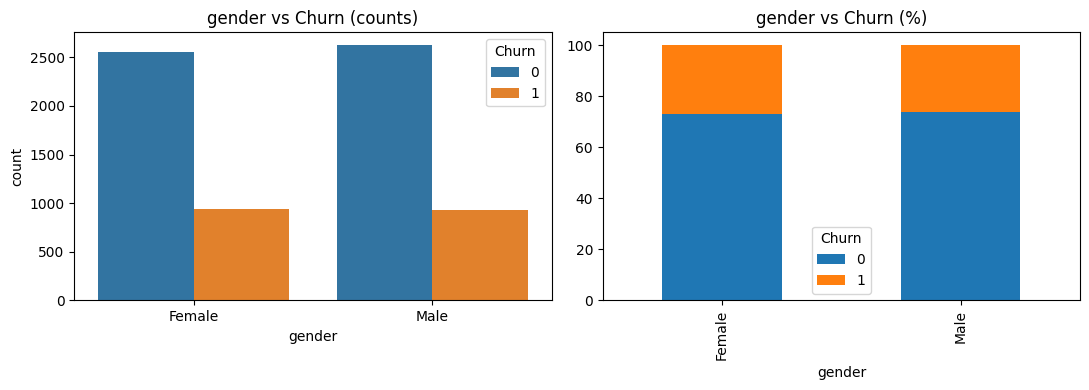

In [12]:
churn_plot('gender')

Churn rate (%) by SeniorCitizen:
Churn             0     1
SeniorCitizen            
0              76.4  23.6
1              58.3  41.7


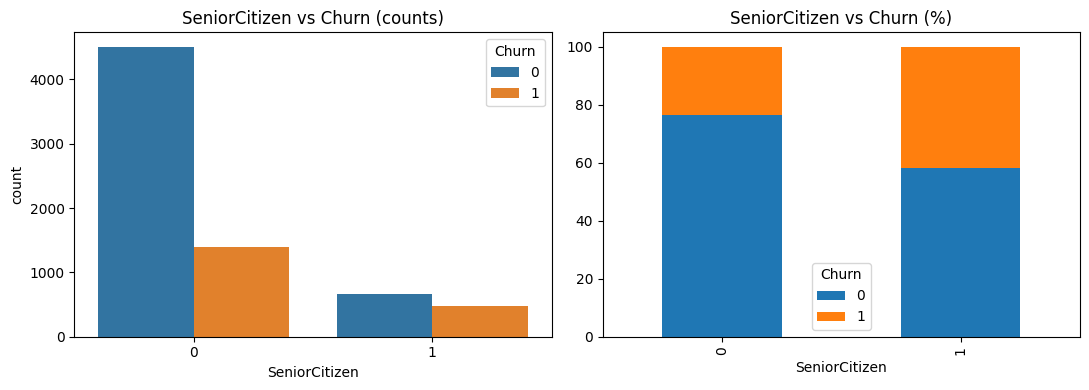

In [13]:
churn_plot('SeniorCitizen')

Churn rate (%) by Partner:
Churn       0     1
Partner            
No       67.0  33.0
Yes      80.3  19.7


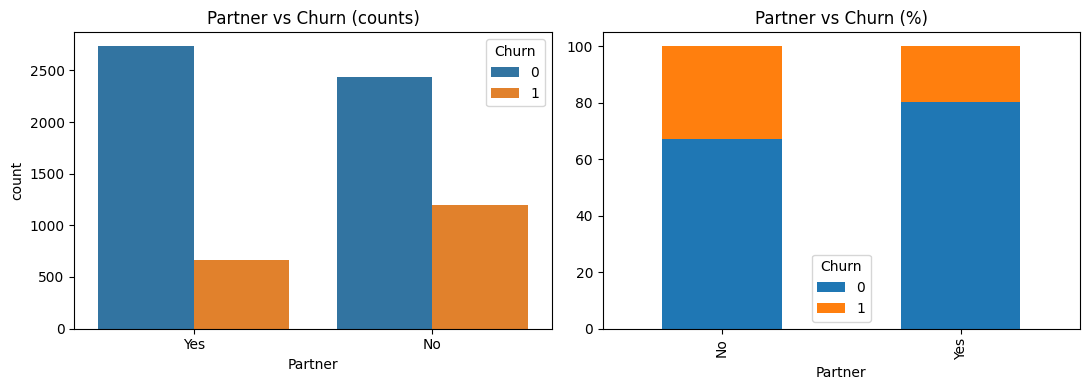

In [14]:
churn_plot('Partner')

Churn rate (%) by Dependents:
Churn          0     1
Dependents            
No          68.7  31.3
Yes         84.5  15.5


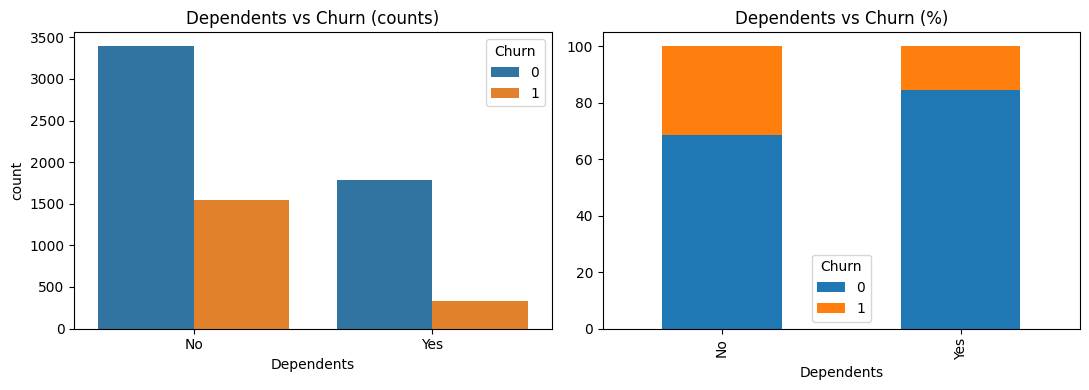

In [15]:
churn_plot('Dependents')

Churn rate (%) by PhoneService:
Churn            0     1
PhoneService            
No            75.1  24.9
Yes           73.3  26.7


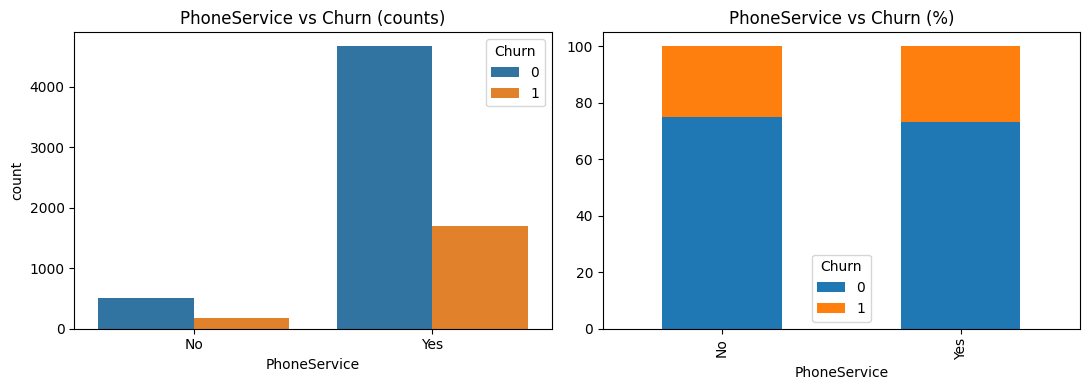

In [16]:
churn_plot('PhoneService')

Churn rate (%) by Contract:
Churn              0     1
Contract                  
Month-to-month  57.3  42.7
One year        88.7  11.3
Two year        97.2   2.8


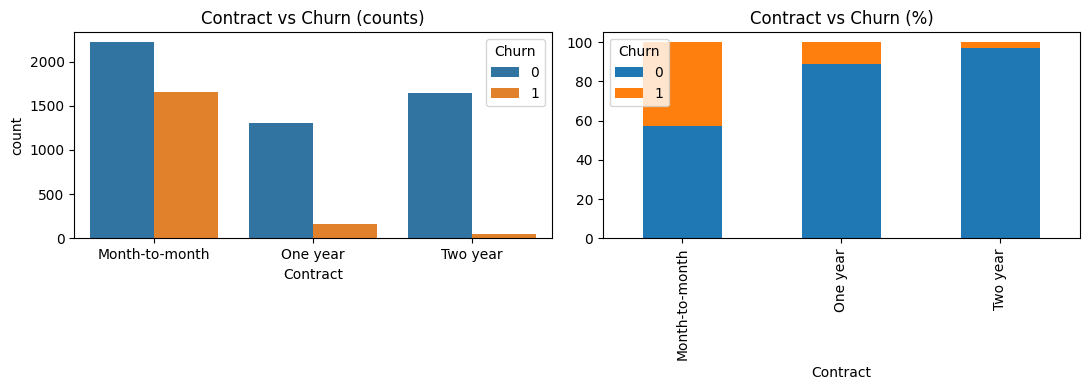

In [17]:
churn_plot('Contract')


Churn rate (%) by PaperlessBilling:
Churn                0     1
PaperlessBilling            
No                83.7  16.3
Yes               66.4  33.6


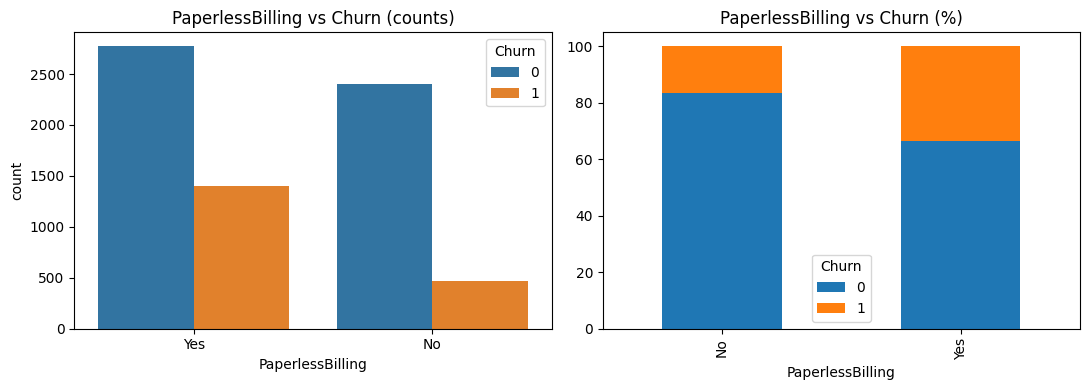

In [18]:
churn_plot('PaperlessBilling')


Churn rate (%) by PaymentMethod:
Churn                         0     1
PaymentMethod                        
Bank transfer (automatic)  83.3  16.7
Credit card (automatic)    84.8  15.2
Electronic check           54.7  45.3
Mailed check               80.9  19.1


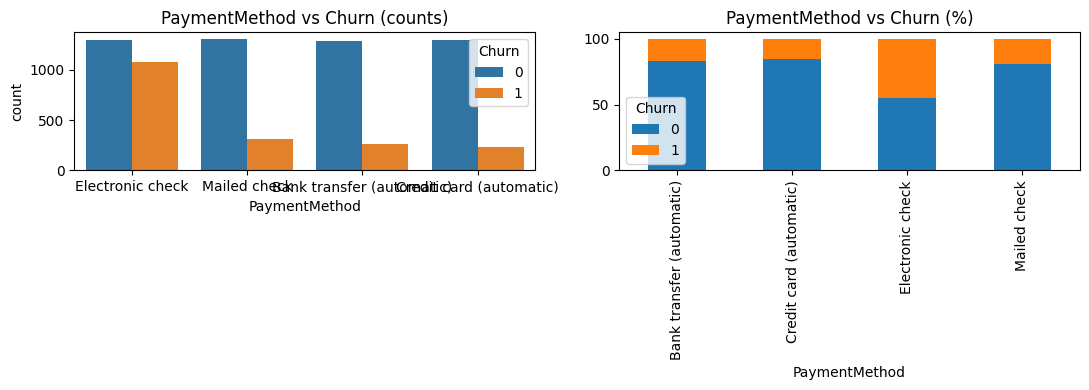

In [19]:
churn_plot('PaymentMethod')

Churn rate (%) by PaymentMethod:
Churn                         0     1
PaymentMethod                        
Bank transfer (automatic)  83.3  16.7
Credit card (automatic)    84.8  15.2
Electronic check           54.7  45.3
Mailed check               80.9  19.1


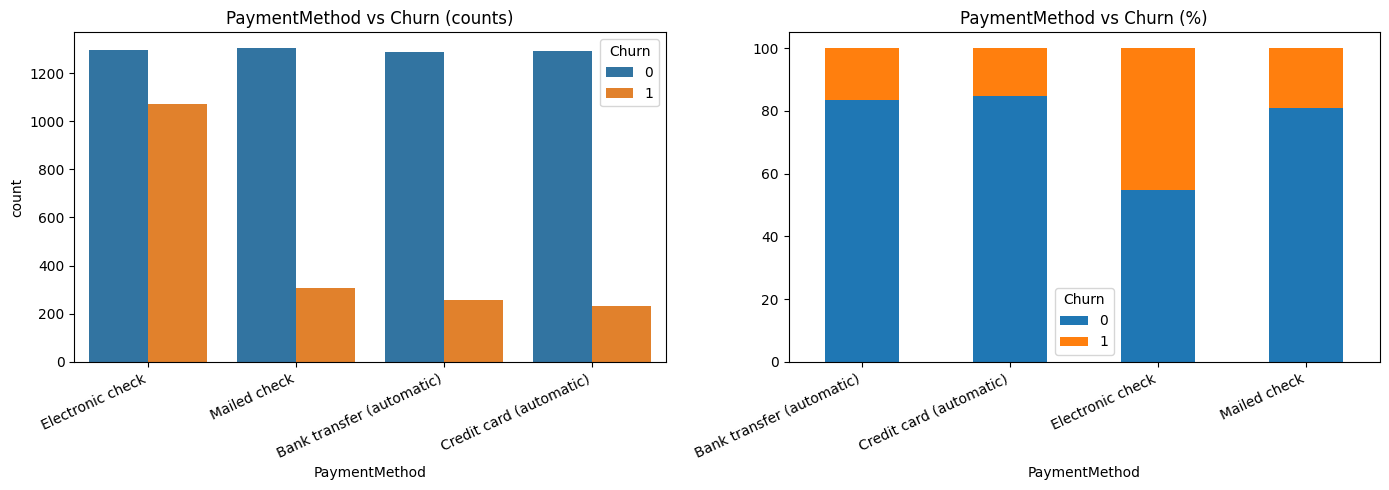

In [20]:
ct = pd.crosstab(data['PaymentMethod'], data['Churn'], normalize='index') * 100
print("Churn rate (%) by PaymentMethod:")
print(ct.round(1))

fig, ax = plt.subplots(1, 2, figsize=(14, 5))

sns.countplot(data=data, x='PaymentMethod', hue='Churn', ax=ax[0])
ax[0].set_title('PaymentMethod vs Churn (counts)')
ax[0].tick_params(axis='x', rotation=25)
plt.setp(ax[0].get_xticklabels(), ha='right')
ax[0].legend(title='Churn', loc='upper right')

ct.plot(kind='bar', stacked=True, ax=ax[1])
ax[1].set_title('PaymentMethod vs Churn (%)')
ax[1].tick_params(axis='x', rotation=25)
plt.setp(ax[1].get_xticklabels(), ha='right')

plt.tight_layout()
plt.show()